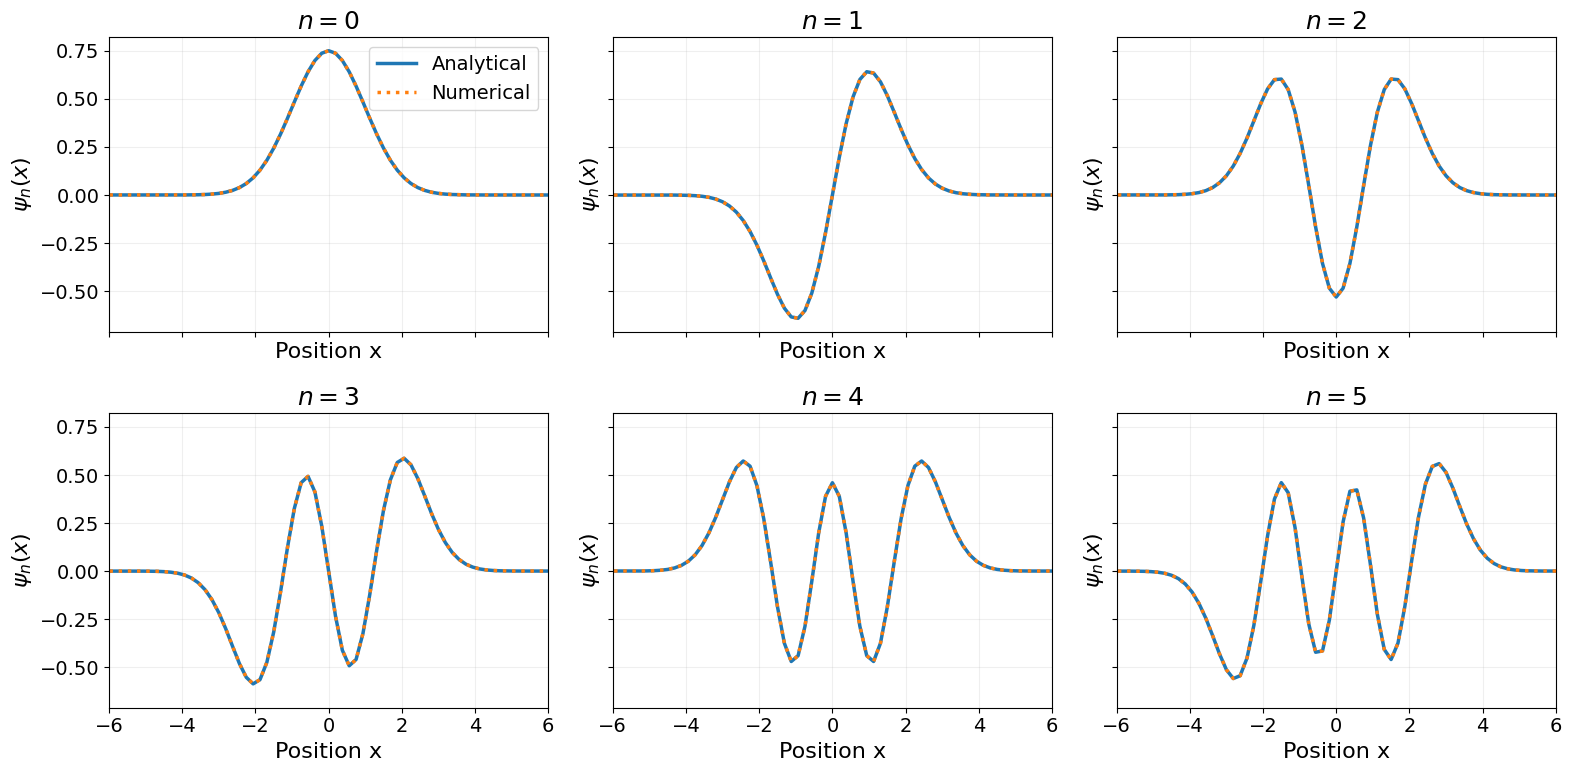

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 20,
})

folder = Path.cwd()
if not (folder / "harmonic.py").exists():
    folder = folder.parent
sys.path.insert(0, str(folder))

from harmonic import HarmonicOscillator

plt.rcParams.update({"font.size": 16})

ho = HarmonicOscillator(boundary=(-12, 12), n=128)
x = ho.xi()
dx = x[1] - x[0]

energies, basis = ho.eigenstates()

fig, axes = plt.subplots(
    2, 3, figsize=(16, 8), sharex=True, sharey=True
)

for level, ax in enumerate(axes.flat):
    analytical = ho.anal_eigenstates(level)

    # Convert numerical eigenvector to continuum normalization
    numerical = basis[:, level] / np.sqrt(dx)

    # Align the arbitrary overall phase/sign
    overlap = np.vdot(analytical, numerical)
    numerical *= np.exp(-1j * np.angle(overlap))

    ax.plot(x, analytical, "-", lw=2.5, label="Analytical")
    ax.plot(x, numerical.real, ":", lw=2.5, label="Numerical")

    ax.set_title(rf"$n={level}$")
    ax.set_xlabel("Position x")
    ax.set_ylabel(r"$\psi_n(x)$")
    ax.set_xlim(-6, 6)
    ax.grid(alpha=0.2)

axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [3]:
for level in range(6):
    print(
        f"n={level}: "
        f"analytical E={level + 0.5:.6f}, "
        f"numerical E={energies[level]:.6f}"
    )

n=0: analytical E=0.500000, numerical E=0.500000
n=1: analytical E=1.500000, numerical E=1.500000
n=2: analytical E=2.500000, numerical E=2.500000
n=3: analytical E=3.500000, numerical E=3.500000
n=4: analytical E=4.500000, numerical E=4.500000
n=5: analytical E=5.500000, numerical E=5.500000
